In [68]:
# from _future_ import annotations

import operator
from typing import TypedDict, List, Annotated

from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
import os
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_groq import ChatGroq

import psycopg
from psycopg.rows import dict_row
from langgraph.checkpoint.postgres import PostgresSaver
from dotenv import load_dotenv

load_dotenv()

True

In [69]:
def get_database_url():
    database_url = os.getenv("DATABASE_URL")

    if not database_url:
        raise ValueError(
            "DATABASE_URL environment variable is not set. Please set it to your PostgreSQL connection string."
        )

    if "sslmode" not in database_url:
        separator = "&" if "?" in database_url else "?"
        database_url = f"{database_url}{separator}sslmode=require"

    return database_url

In [70]:
GROQ_API_KEY = os.getenv("GROQ_API_KEY")
if not GROQ_API_KEY:
    raise ValueError(
        "GROQ_API_KEY environment variable is not set. Please set it to your Groq API key."
    )

In [71]:
class Task(BaseModel):
    id: int
    title: str
    brief: str = Field(..., description="What to cover")

In [72]:
class Plan(BaseModel):
    blog_title: str
    tasks: List[Task]

In [73]:
class State(TypedDict):
    topic: str
    plan: Plan
    sections: Annotated[List[str], operator.add]
    final: str

In [74]:
llm = ChatGroq(
    model = "openai/gpt-oss-120b",
    api_key = GROQ_API_KEY
)

In [75]:
def orchestrator(state: State) -> dict:

    plan = llm.with_structured_output(Plan).invoke(
        [
            SystemMessage(
                content=(
                    "Create a blog plan with 5-7 sections on the following topic."
                )
            ),
            HumanMessage(content=f"Topic: {state['topic']}"),
        ]
    )
    return {"plan": plan}

In [76]:
def fanout(state: State):
    return [Send("worker", {"task": task, "topic": state["topic"], "plan": state["plan"]}) 
            for task in state["plan"].tasks]

In [77]:
def worker(payload: dict) -> dict:
    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    blog_title = plan.blog_title

    section_md = llm.invoke(
        [
            SystemMessage(content="Write one clean Markdown section."),
            HumanMessage(
                content=(
                    f"Blog: {blog_title}\n"
                    f"Topic: {topic}\n\n"
                    f"Section: {task.title}\n"
                    f"Brief: {task.brief}\n\n"
                    "Return only the section content in Markdown."
                )
            ),
        ]
    ).content.strip()

    return {"sections": [section_md]}

In [78]:
from pathlib import Path
import re

def reducer(state: State) -> dict:
    title = state["plan"].blog_title
    body = "\n\n".join(state["sections"]).strip()

    final_md = f"# {title}\n\n{body}\n"

    filename = re.sub(r'[<>:"/\\|?*]', "", title)
    filename = filename.strip().lower().replace(" ", "_") + ".md"

    output_path = Path.cwd() / filename
    output_path.write_text(final_md, encoding="utf-8")

    print(f"Markdown file saved at: {output_path.resolve()}")

    return {"final": final_md}


In [79]:
g = StateGraph(State)
g.add_node("orchestrator", orchestrator)
g.add_node("worker", worker)
g.add_node("reducer", reducer)

g.add_edge(START, "orchestrator")
g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

In [80]:
DATABASE_URL = get_database_url()

_conn = psycopg.connect(
    DATABASE_URL,
    autocommit=True,
    row_factory=dict_row
)

checkpointer = PostgresSaver(_conn)
checkpointer.setup()

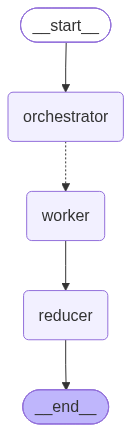

In [81]:
app = g.compile(checkpointer=checkpointer)

app

In [82]:
config = {
    "configurable": {
        "thread_id": "test_thread_id"
    }
}

In [83]:
out = app.invoke({"topic": "Write a blog on Self Attention", "sections": []}, config=config)

Markdown file saved at: C:\Users\DAYACHAND\Desktop\AgentWriter-AI\notebooks\demystifying_self-attention_how_it_powers_modern_ai.md


In [84]:
out

{'topic': 'Write a blog on Self Attention',
 'plan': Plan(blog_title='Demystifying Self-Attention: How It Powers Modern AI', tasks=[Task(id=1, title='Introduction to Attention Mechanisms', brief='Explain the motivation behind attention, its origins in sequence modeling, and why traditional RNNs struggled with long-range dependencies.'), Task(id=2, title='The Core Idea of Self-Attention', brief='Define self-attention, illustrate how each token relates to every other token in a sequence, and introduce the query-key-value formulation.'), Task(id=3, title='Mathematical Formulation and Scaled Dot‑Product', brief='Derive the scaled dot‑product attention equation, discuss the role of scaling, softmax, and the resulting attention matrix.'), Task(id=4, title='Multi‑Head Attention: Parallel Perspectives', brief='Explain why multiple attention heads are used, how they capture diverse patterns, and the process of concatenation and linear projection.'), Task(id=5, title='Positional Encoding: Giving